In [1]:
import pandas as pd
import numpy as np
import sys
from pathlib import Path
sys.path.insert(0, str(Path("..").resolve()))
import eda

In [8]:
n_obj = 3
n_items = 20
n_selected = 5
rho = 0.3
data = np.load(f'problems/items_{n_obj}obj_{n_items}items_{rho}rho_allneg.npz')
items = data['items']
capacity = data['capacity']

In [ ]:
eda_run = eda.KnapsackEDA(
    items=items,
    capacity=capacity,
    n_selected=n_selected,
    n_obj=n_obj,
    pop_size=1000,
    generations=100,
    max_no_improve_gen=3,
    max_row_diff=0.1,
    seed=1123,
)
results = eda_run.run()
pf_eda = results["converged_pf_table"][-1]
ps_eda = results["converged_pf_population_table"][-1]
np.savez(f"results/eda_{n_obj}obj_{n_items}items_{rho}rho_allneg.npz", pf_eda)

In [9]:
pf_exact = np.load(f"results/exact_front_{n_obj}obj_{n_items}items_{rho}rho_allneg.npz")["F"]
pf_ks = np.load(f"results/KS_{n_obj}obj_{n_items}items_{rho}rho_allneg.npz")["pf"]
pf_eda = np.load(f"results/eda_{n_obj}obj_{n_items}items_{rho}rho_allneg.npz")["arr_0"]
pf_nsga2 = np.load(f"results/nsga2_{n_obj}obj_{n_items}items_{rho}rho_allneg.npz")["F"]
pf_nsga3 = np.load(f"results/nsga3_{n_obj}obj_{n_items}items_{rho}rho_allneg.npz")["F"]
pf_spea2 = np.load(f"results/spea2_{n_obj}obj_{n_items}items_{rho}rho_allneg.npz")["F"]

In [10]:
print(pf_exact.shape)
print(pf_ks.shape)
print(pf_eda.shape)
print(pf_nsga2.shape)
print(pf_nsga3.shape)
print(pf_spea2.shape)

(278, 3)
(278, 3)
(260, 3)
(278, 3)
(278, 3)
(278, 3)


In [7]:
np.allclose(
    np.unique(np.round(pf_nsga3), axis=0),
    np.unique(np.round(pf_exact), axis=0),
)

True

In [ ]:
pf_eda_pd = pd.read_csv("../card_game/eda_results/pf_trial0.csv", header=None)
pf_eda = np.array(pf_eda_pd)
pf_eda = np.load("problems/pf_1_eda.npz")["arr_0"]
pf_KirlikSayin_no_constraint = np.load("problems/pf_1_no_constraint.npz")["pf"]
pf_KirlikSayin = np.load("problems/pf_1.npz")["pf"]
pf_TV = np.load("problems/pf_1_TV.npz")["pf"]

In [ ]:
pf_eda.shape

In [ ]:
pf_KirlikSayin.shape

In [ ]:
pf_TV.shape

In [ ]:
np.allclose(pf_KirlikSayin, pf_KirlikSayin_no_constraint)

In [ ]:
def rows_not_in(a, b, atol=1e-8, rtol=1e-5):
    """Rows of `a` that do not appear (approx.) in `b`."""
    mask = np.ones(len(a), dtype=bool)
    for i, row in enumerate(a):
        if np.any(np.all(np.isclose(b, row, atol=atol, rtol=rtol), axis=1)):
            mask[i] = False
    return a[mask], np.where(mask)[0]
missing, idx = rows_not_in(pf_eda[:, :n_obj], pf_KirlikSayin)
print(idx)      # indices into pf_eda
print(missing)

In [ ]:
missing, idx = rows_not_in(pf_TV, pf_KirlikSayin)
print(idx)     
print(missing)

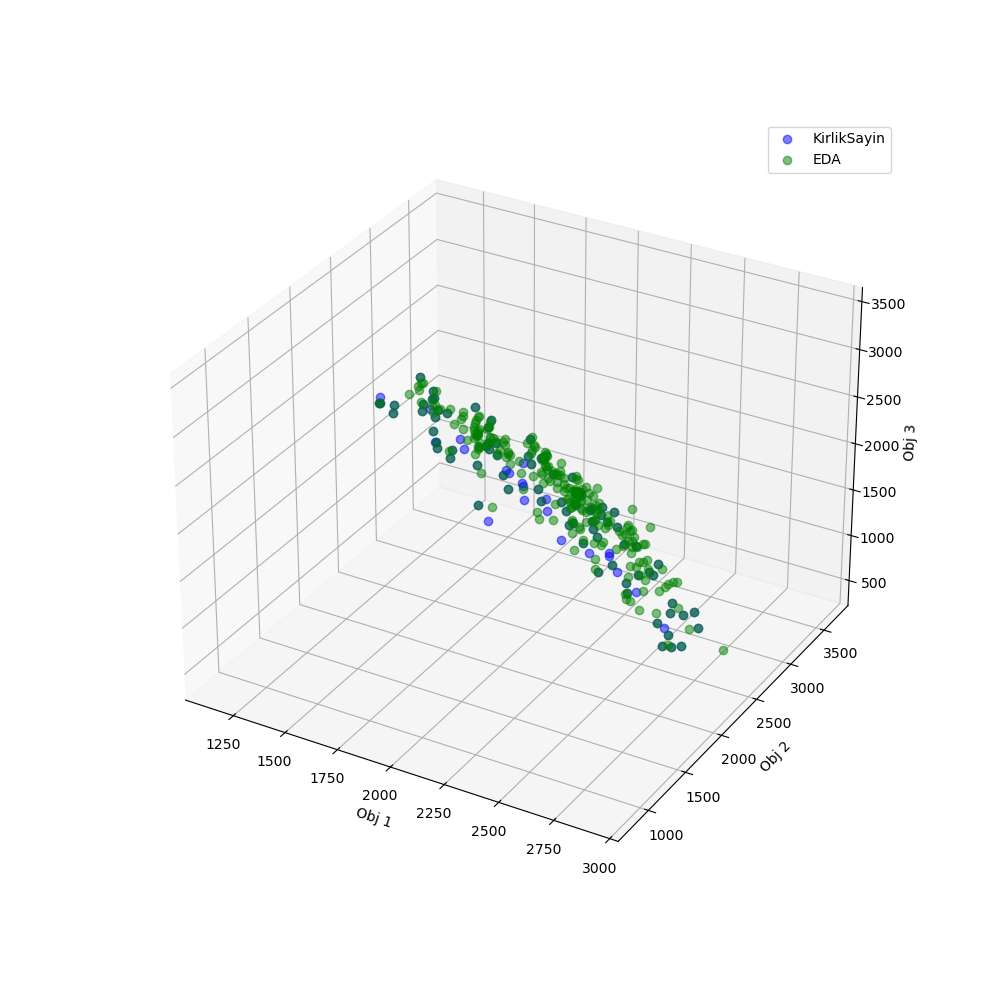

In [5]:
import matplotlib.pyplot as plt
%matplotlib widget
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(projection='3d')
ax.plot(pf_nsga2[:,0], pf_nsga2[:,1], pf_nsga2[:,2], 'bo', alpha=0.5, markersize=6, label="KirlikSayin")
ax.plot(pf_exact[:,0], pf_exact[:,1], pf_exact[:,2], 'go', alpha=0.5, markersize=6, label="EDA")
ax.set_xlabel('Obj 1')
ax.set_ylabel('Obj 2')
ax.set_zlabel('Obj 3')
ax.legend()
plt.show()

In [10]:
from pymoo.indicators.hv import HV

ref_point = np.zeros(n_obj)
hv = HV(ref_point=ref_point)
hv_pf_1 = hv(-pf_moead)
hv_pf_2 = hv(-pf_exact)
print(hv_pf_1)
print(hv_pf_2)

24921450313.0
25844960127.0


In [11]:
def calculate_dominated(pf_predicted, pf_actual, n_obj):
    dominated = np.zeros(len(pf_predicted))
    for i in range(len(pf_predicted)):
        for j in range(len(pf_actual)):
            if np.all(pf_actual[j, :n_obj] >= pf_predicted[i, :n_obj]) and \
                np.any(pf_actual[j, :n_obj] > pf_predicted[i, :n_obj]):
                dominated[i] = 1
                break
    return np.sum(dominated), np.sum(dominated)/len(pf_predicted)

num_dominated, ratio_dominated = calculate_dominated(pf_moead, pf_exact, 3)
print(ratio_dominated)
num_dominated, ratio_dominated = calculate_dominated(pf_exact, pf_moead, 3)
print(ratio_dominated)

0.3114754098360656
0.0
